In [1]:
import math
import random
import statistics
import time
import matplotlib.pyplot as plt

POPULATION_SIZE = 10
ITERATIONS = 50
NUM_RUNS = 1000
FIRST_SEED = 200000
R_MAX = 1.2
MUTATION_RATE_MIN = 0.1
MUTATION_RATE_MAX = 0.5
TOLERANCE = 1e-9
STAGNATION_LIMIT = 5
IMPROVEMENT_TOLERANCE = 1e-6
LOCAL_CHILDREN = 5
FINEST_DECADE = 6

In [2]:
def f1(x):
    return 10 - (x - 3)**2

def f2(x):
    return 10 - (-x * math.sin(math.sqrt(abs(x))) + 418.9828872724337)

def f3(x):
    return 10 - (x**2 - 10 * math.cos(2 * math.pi * x) + 10)

FUNCTIONS = {
    "f1": (f1, -5, 10, 10),
    "f2": (f2, -500, 500, 10),
    "f3": (f3, -5.12, 5.12, 10),
}

In [3]:
def run_baseline(population, objective_function, lower, upper):
    populations = [population]
    values = [objective_function(x) for x in population]
    top = max(range(len(population)), key=values.__getitem__)
    best_x, best_f = population[top], values[top]
    history = [best_f]

    for _ in range(ITERATIONS):
        new_population = []
        new_values = []
        for _ in range(POPULATION_SIZE):
            ia, ib, ic = random.sample(range(len(population)), 3)
            c = (population[ia] + population[ib] + population[ic]) / 3
            ip = ia
            if values[ib] > values[ip]:
                ip = ib
            if values[ic] > values[ip]:
                ip = ic
            r = random.uniform(0, R_MAX)
            xnew = c + r * (population[ip] - c)

            xnew = max(lower, min(upper, xnew))
            new_population.append(xnew)
            new_values.append(objective_function(xnew))

        population, values = new_population, new_values
        populations.append(population)

        top = max(range(len(population)), key=values.__getitem__)
        if values[top] > best_f:
            best_x, best_f = population[top], values[top]

        history.append(best_f)

    return {
        "best_x": best_x,
        "best_f": best_f,
        "history": history,
        "populations": populations
    }

In [4]:
def run_improvement(population, objective_function, lower, upper):
    mutation_std = 0.1 * (upper - lower)
    populations = [population]
    values = [objective_function(x) for x in population]
    top = max(range(len(population)), key=values.__getitem__)
    best_x, best_f = population[top], values[top]
    history = [best_f]
    stagnation = 0

    for _ in range(ITERATIONS):
        if stagnation >= STAGNATION_LIMIT:
            top = max(range(len(population)), key=values.__getitem__)
            population = [population[top]] + [
                random.uniform(lower, upper) for _ in range(POPULATION_SIZE - 1)
            ]
            values = [objective_function(x) for x in population]
            stagnation = 0

        spread = (max(population) - min(population)) / (upper - lower)
        mutation_rate = MUTATION_RATE_MIN + (MUTATION_RATE_MAX - MUTATION_RATE_MIN) * (1 - min(1, spread))
        top = max(range(len(population)), key=values.__getitem__)
        new_population = list(population)
        new_values = list(values)
        for _ in range(POPULATION_SIZE):
            ia, ib, ic = random.sample(range(len(population)), 3)
            c = (population[ia] + population[ib] + population[ic]) / 3
            ip = ia
            if values[ib] > values[ip]:
                ip = ib
            if values[ic] > values[ip]:
                ip = ic
            r = random.uniform(0, R_MAX)
            xnew = c + r * (population[ip] - c)

            if random.random() < mutation_rate:
                xnew += random.gauss(0, mutation_std)

            xnew = max(lower, min(upper, xnew))
            fnew = objective_function(xnew)
            if fnew > new_values[ip]:
                new_population[ip] = xnew
                new_values[ip] = fnew

        for _ in range(LOCAL_CHILDREN):
            scale = (upper - lower) * 10 ** (-random.uniform(1, FINEST_DECADE))
            xnew = best_x + random.gauss(0, scale)
            xnew = max(lower, min(upper, xnew))
            fnew = objective_function(xnew)
            if fnew > new_values[top]:
                new_population[top] = xnew
                new_values[top] = fnew

        population, values = new_population, new_values
        populations.append(population)

        previous_best = best_f
        top = max(range(len(population)), key=values.__getitem__)
        if values[top] > best_f:
            best_x, best_f = population[top], values[top]

        if best_f > previous_best + IMPROVEMENT_TOLERANCE:
            stagnation = 0
        else:
            stagnation += 1

        history.append(best_f)

    return {
        "best_x": best_x,
        "best_f": best_f,
        "history": history,
        "populations": populations
    }

In [5]:
ALGORITHMS = {
    "Baseline": run_baseline,
    "Improvement": run_improvement,
}

def initial_population(lower, upper):
    width = (upper - lower) / POPULATION_SIZE
    return [
        random.uniform(lower + k * width, lower + (k + 1) * width)
        for k in range(POPULATION_SIZE)
    ]

def run_with_seed(runner, seed, objective, lower, upper):
    random.seed(seed)
    return runner(initial_population(lower, upper), objective, lower, upper)

results = {}
execution_times = {}
for name, (objective, lower, upper, optimum) in FUNCTIONS.items():
    results[name] = {}
    execution_times[name] = {}
    for algorithm, runner in ALGORITHMS.items():
        start_time = time.perf_counter()
        results[name][algorithm] = [
            run_with_seed(runner, FIRST_SEED + run, objective, lower, upper)
            for run in range(NUM_RUNS)
        ]
        execution_times[name][algorithm] = time.perf_counter() - start_time

In [6]:
best_values = {
    function: {
        algorithm: [result["best_f"] for result in runs]
        for algorithm, runs in by_algorithm.items()
    }
    for function, by_algorithm in results.items()
}

for function, by_algorithm in best_values.items():
    print(f"EVALUATION METRICS: {function}")
    print(f"{'Algorithm':<28} {'Best':>10} {'Average':>10} {'Worst':>10} {'Std':>10} {'Time (s)':>9}")
    print("-" * 82)
    for algorithm, values in by_algorithm.items():
        print(
            f"{algorithm:<28} "
            f"{max(values):>10.6f} "
            f"{statistics.mean(values):>10.6f} "
            f"{min(values):>10.6f} "
            f"{statistics.stdev(values):>10.6f} "
            f"{execution_times[function][algorithm]:>9.4f}"
        )
    print()

EVALUATION METRICS: f1
Algorithm                          Best    Average      Worst        Std  Time (s)
----------------------------------------------------------------------------------
Baseline                      10.000000   9.997155   9.724341   0.016774    1.3983
Improvement                   10.000000  10.000000  10.000000   0.000000    1.8025

EVALUATION METRICS: f2
Algorithm                          Best    Average      Worst        Std  Time (s)
----------------------------------------------------------------------------------
Baseline                      10.000000 -43.135438 -286.141827  65.184068    1.4110
Improvement                   10.000000   9.999951   9.952923   0.001489    1.8070

EVALUATION METRICS: f3
Algorithm                          Best    Average      Worst        Std  Time (s)
----------------------------------------------------------------------------------
Baseline                      10.000000   9.698328   5.616630   0.518826    1.4560
Improvement    

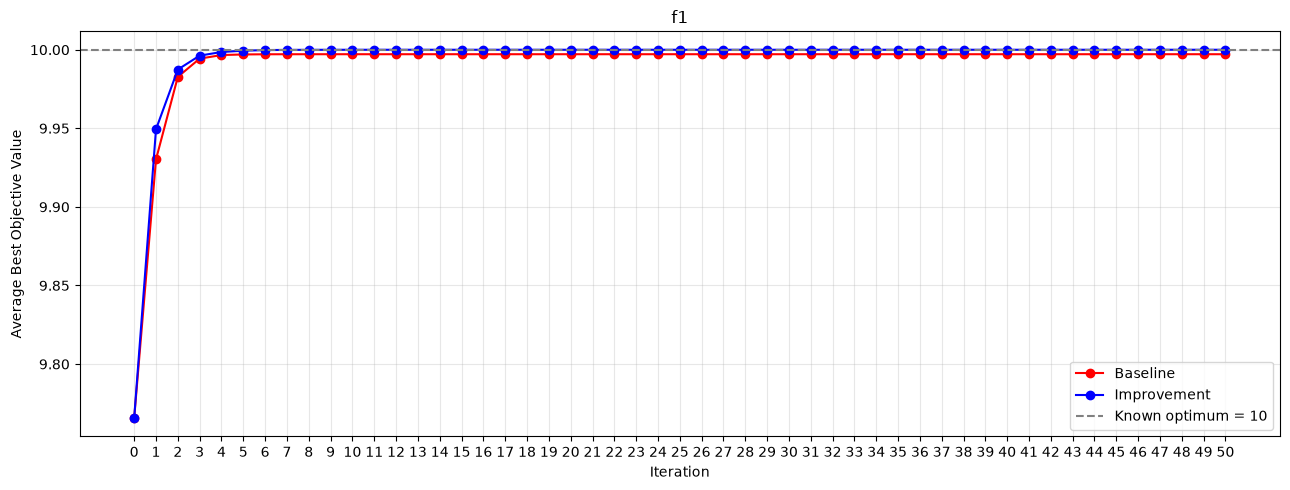

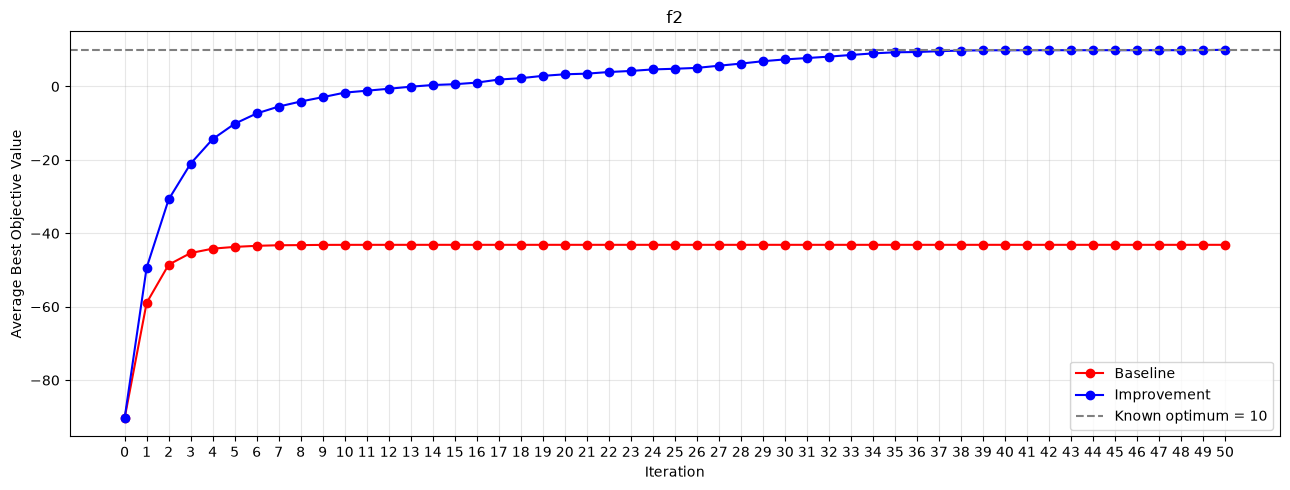

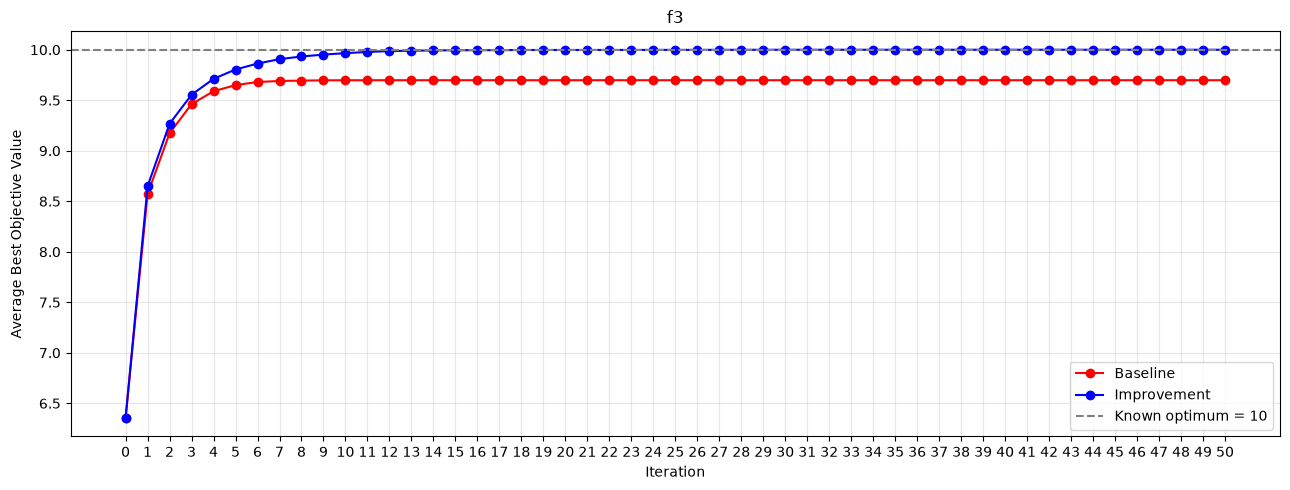

In [7]:
mean_history = {
    function: {
        algorithm: [
            statistics.mean(result["history"][i] for result in runs)
            for i in range(ITERATIONS + 1)
        ]
        for algorithm, runs in by_algorithm.items()
    }
    for function, by_algorithm in results.items()
}

COLORS = ["red", "blue"]

for function, by_algorithm in mean_history.items():
    optimum = FUNCTIONS[function][3]
    plt.figure(figsize=(13, 5))

    for (algorithm, history), color in zip(by_algorithm.items(), COLORS):
        plt.plot(
            range(ITERATIONS + 1),
            history,
            marker="o",
            color=color,
            label=algorithm
        )

    plt.axhline(
        y=optimum,
        linestyle="--",
        color="gray",
        label=f"Known optimum = {optimum}"
    )

    plt.title(function)
    plt.xlabel("Iteration")
    plt.ylabel("Average Best Objective Value")
    plt.xticks(range(ITERATIONS + 1))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()